<!-- Copyright (c) 2026 Robotics and AI Institute LLC dba RAI Institute. All rights reserved. -->

# Segmentation Label Color Visualizer

Use this notebook to inspect (and tweak) the label colors defined in `src/sem_map/config/seg_layers/*.yaml`. Run the helper functions below to load any of the YAML configs and display the palette for each class.


In [3]:
from pathlib import Path
from typing import List, Optional
import sys

import matplotlib.pyplot as plt
import matplotlib.patches as patches
import yaml

# Make sure `sem_map` package is importable (add scripts dir to PYTHONPATH)
notebook_dir = Path().resolve()
scripts_dir = notebook_dir.parent.parent
sys.path.insert(0, str(scripts_dir))

from sem_map.perception.common import get_workspace_root

WORKSPACE_ROOT = get_workspace_root()
SEG_LAYER_DIR = WORKSPACE_ROOT / "src/sem_map/config/seg_layers"


def list_seg_layers() -> List[str]:
    """Return available seg_layer YAML filenames (sorted)."""
    if not SEG_LAYER_DIR.exists():
        raise FileNotFoundError(f"Seg-layer directory missing: {SEG_LAYER_DIR}")
    return sorted(p.name for p in SEG_LAYER_DIR.glob("*.yaml"))


def load_seg_layer(name: str) -> dict:
    """Load a seg_layer YAML file by name (with or without .yaml suffix)."""
    name = name if name.endswith(".yaml") else f"{name}.yaml"
    path = SEG_LAYER_DIR / name
    if not path.exists():
        raise FileNotFoundError(f"No seg_layer config at: {path}")
    with path.open("r") as f:
        return yaml.safe_load(f)


def plot_seg_layer(name: str, figsize: Optional[tuple] = None) -> None:
    """Visualize label IDs, names, and RGB colors for the given seg layer."""
    data = load_seg_layer(name)
    categories = data.get("categories", [])
    if not categories:
        raise ValueError(f"No categories found in {name}")

    labels = [cat.get("name", f"id_{cat.get('id', '?')}") for cat in categories]
    ids = [cat.get("id", idx) for idx, cat in enumerate(categories)]
    colors = [cat.get("color", [128, 128, 128]) for cat in categories]
    is_things = [bool(cat.get("isthing", False)) for cat in categories]

    num_cats = len(categories)
    figsize = figsize or (10, max(3, num_cats * 0.4))

    fig, ax = plt.subplots(figsize=figsize)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, num_cats)
    ax.axis("off")

    for idx, (label_id, label_name, color_rgb, is_thing) in enumerate(zip(ids, labels, colors, is_things)):
        rgb = [min(max(c, 0), 255) / 255.0 for c in color_rgb]
        rect = patches.Rectangle((0, idx), width=0.2, height=0.9, color=rgb)
        ax.add_patch(rect)
        ax.text(0.23, idx + 0.45, f"{label_id:>2}", va="center", ha="left", fontsize=10, fontweight="bold")
        label_extra = " (thing)" if is_thing else ""
        ax.text(0.32, idx + 0.45, label_name + label_extra, va="center", ha="left", fontsize=10)
        ax.text(0.78, idx + 0.45, str(color_rgb), va="center", ha="left", fontsize=9, color="gray")

    ax.set_title(f"Seg Layer: {data.get('name', name)} ({num_cats} classes)")
    plt.show()


# Optional convenience: list available YAML files
print("Available seg layers:")
for filename in list_seg_layers():
    print(f"  - {filename}")

print("\nCall plot_seg_layer('<filename.yaml>') to visualize a config.")


/usr/local/lib/python3.10/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Available seg layers:
  - city_27.yaml
  - cityscapes_19.yaml
  - cocostuff_27.yaml
  - factory_3.yaml
  - indoor_trail_3.yaml
  - office_3.yaml
  - trail_27.yaml
  - trail_5.yaml

Call plot_seg_layer('<filename.yaml>') to visualize a config.


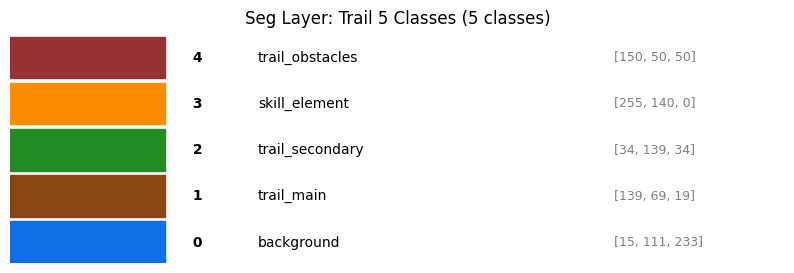

In [5]:
plot_seg_layer("trail_5.yaml")